In [49]:
print("Welcome to ShadowFox Netflix Data Analysis!")

Welcome to ShadowFox Netflix Data Analysis!


In [50]:
import pandas as pd

df = pd.read_csv("netflix_titles.csv")

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Number of rows and columns: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [51]:
print("Column names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

Column names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

Missing values:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


In [52]:
# Fill missing text values
df["director"] = df["director"].fillna("Unknown")
df["cast"] = df["cast"].fillna("Unknown")
df["country"] = df["country"].fillna("Unknown")
df["rating"] = df["rating"].fillna("Not Rated")
df["duration"] = df["duration"].fillna("Unknown")

# Remove duplicate records
df = df.drop_duplicates()

# Convert date column into date format
df["date_added"] = pd.to_datetime(
    df["date_added"].str.strip(),
    errors="coerce"
)

print("Data cleaning completed!")
print("\nMissing values after cleaning:")
print(df.isnull().sum())

Data cleaning completed!

Missing values after cleaning:
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         0
listed_in        0
description      0
dtype: int64


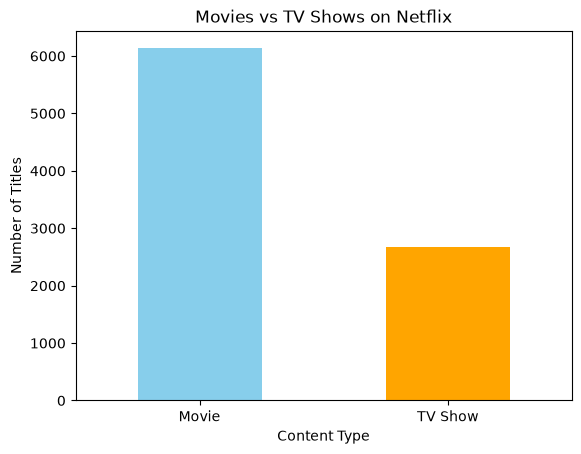

In [53]:
import matplotlib.pyplot as plt

type_counts = df["type"].value_counts()

type_counts.plot(kind="bar", color=["skyblue", "orange"])

plt.title("Movies vs TV Shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.xticks(rotation=0)
plt.show()

country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


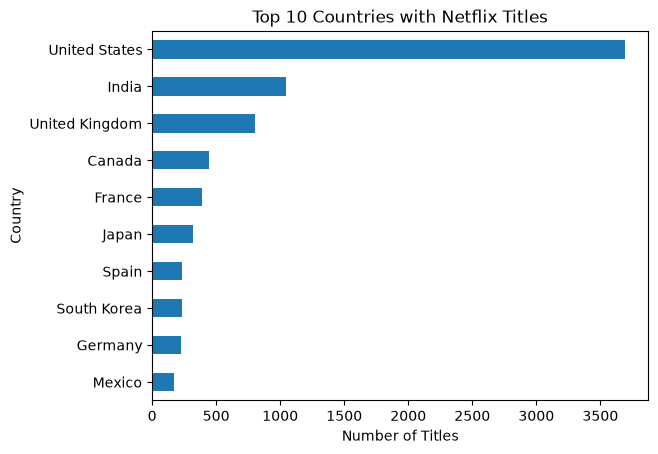

In [54]:
# Find the top 10 countries
countries = df["country"].str.split(", ").explode()

top_countries = countries[countries != "Unknown"].value_counts().head(10)

print(top_countries)

# Create a bar chart
top_countries.sort_values().plot(kind="barh")

plt.title("Top 10 Countries with Netflix Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Country")

plt.show()

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


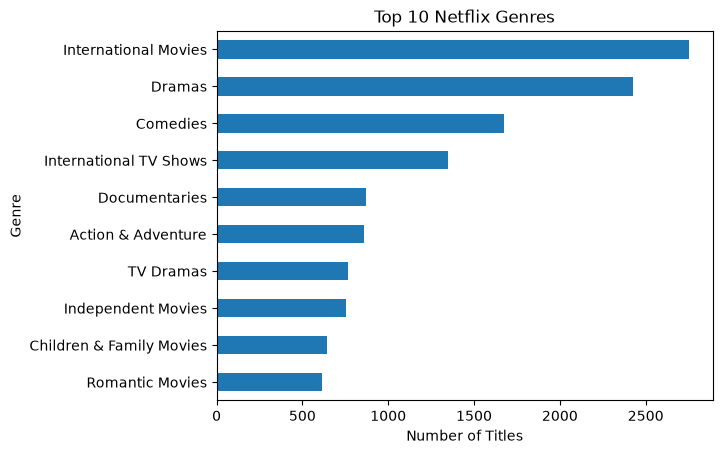

In [55]:
# Separate the genres
genres = df["listed_in"].str.split(", ").explode()

# Count the top 10 genres
top_genres = genres.value_counts().head(10)

print(top_genres)

# Create a graph
top_genres.sort_values().plot(kind="barh")

plt.title("Top 10 Netflix Genres")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")

plt.show()

year_added
2008.0       2
2009.0       2
2010.0       1
2011.0      13
2012.0       3
2013.0      11
2014.0      24
2015.0      82
2016.0     429
2017.0    1188
2018.0    1649
2019.0    2016
2020.0    1879
2021.0    1498
Name: count, dtype: int64


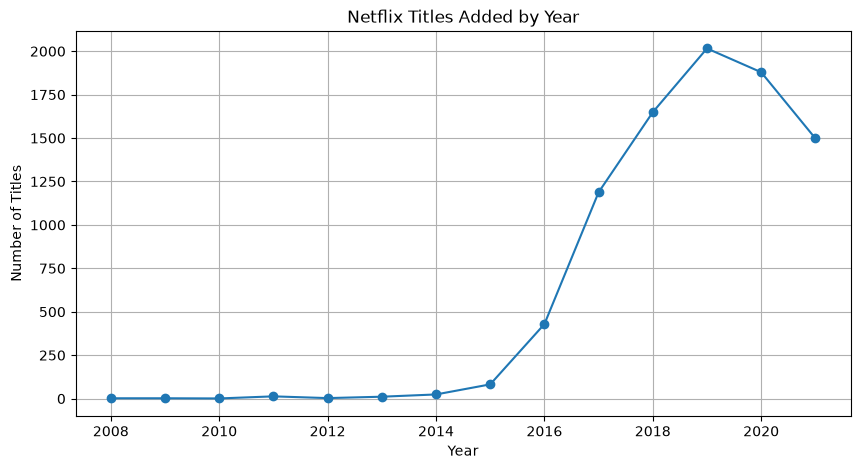

In [56]:
# Convert date_added into year
df["year_added"] = df["date_added"].dt.year

# Count titles added each year
year_counts = df["year_added"].value_counts().sort_index()

print(year_counts)

# Create a line graph
year_counts.plot(kind="line", marker="o", figsize=(10, 5))

plt.title("Netflix Titles Added by Year")
plt.xlabel("Year")
plt.ylabel("Number of Titles")
plt.grid(True)

plt.show()

Movie duration statistics:
count    6128.000000
mean       99.577187
std        28.290593
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: duration_minutes, dtype: float64


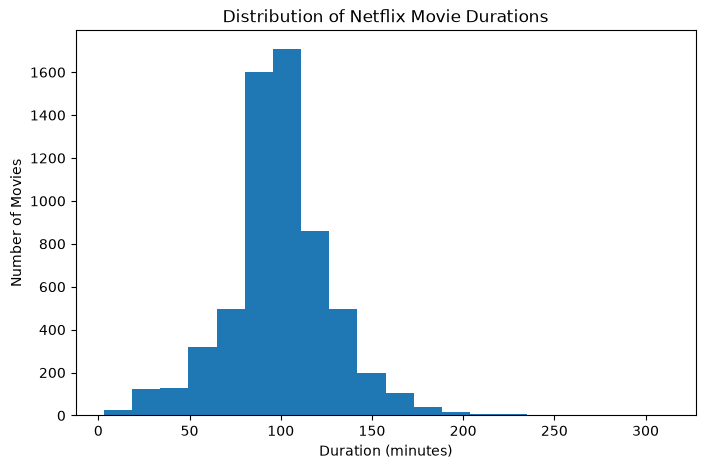

In [57]:
# Select movies only
movies = df[df["type"] == "Movie"].copy()

# Extract duration in minutes
movies["duration_minutes"] = (
    movies["duration"].str.extract(r"(\d+)").astype(float)
)

# Display summary
print("Movie duration statistics:")
print(movies["duration_minutes"].describe())

# Create a histogram
movies["duration_minutes"].dropna().plot(
    kind="hist", bins=20, figsize=(8, 5)
)

plt.title("Distribution of Netflix Movie Durations")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Movies")
plt.show()